# 04 분류 

## 01. 분류의 개요

- 지도학습 : 명시적인 정답이 있는 데이터가 주어진 상태에서 학습하는 방식
- 그중 대표적인 유형이 분류
- 학습 데이터의 피처와 레이블(결정 값, 클래스 값)을 알고리즘으로 학습해 모델을 만들고, 이 모델에 새로운 데이터가 들어왔을 때 아직 모르는 레이블 값을 예측하는 것
- 기존 데이터가 어떤 레이블에 속하는지 패턴을 알고리즘으로 파악해 두었다가, 새로 관측된 데이터의 레이블을 판별하는 작업

분류를 구현하는 알고리즘
- 베이즈 통계와 생성 모델에 기반한 나이브 베이즈
- 독립변수와 종속변수의 선형 관계성에 기반한 로지스틱 회귀
- 데이터 균일도에 따른 규칙 기반의 결정 트리
- 개별 클래스 간의 최대 분류 마진을 효과적으로 찾아주는 서포트 벡터 머신
- 근접 거리를 기준으로 하는 최소 근접 알고리즘
- 심층 연결 기반의 신경망
- 서로 다른(또는 같은) 머신러닝 알고리즘을 결합한 앙상블

### 앙상블

- 앙상블은 서로 다른(또는 같은) 알고리즘을 단순히 결합한 형태도 있지만, 일반적으로는 배깅(Bagging)과 부스팅(Boosting) 방식으로 나뉨
- 대표적 배깅 방식 : 랜덤 포레스트, 뛰어난 예측 성능, 상대적으로 빠른 수행 시간, 유연성 때문에 많이 쓰임
- 최근 부스팅 방식으로 계속 발전하고 있음
- 부스팅 방식 : 그래디언트 부스팅(Gradient Boosting)은 성능은 뛰어나지만 수행 시간이 너무 오래 걸려 최적화 모델 튜닝이 어려운 단점이 있었음, 이를 개선한 XGBoost와 LightGBM 등이 등장하면서, 예측 성능은 한 단계 끌어올리고 수행 시간은 줄여 정형 데이터 분류에서 가장 활용도가 높은 알고리즘이 됨
- 기본 알고리즘 : 결정트리
    - 장점 : 쉽고 유연하게 적용할 수 있고 스케일링이나 정규화 같은 사전 가공의 영향이 적음
    - 단점 : 예측 성능을 높이려고 복잡한 규칙 구조를 만들다 보면 과적합이 생겨 오히려 성능이 떨어질 수 있음 -> 앙상블에서는 이 단점이 오히려 장점이 됨
    - 앙상블은 예측 성능이 상대적으로 떨어지는 약한 학습기를 많이 결합해서 서로의 오류를 보완하고, 오류가 난 부분에 가중치를 계속 업데이트하면서 성능을 올리는데, 결정 트리가 바로 이런 약한 학습기로 적합하기 때문

## 02 결정 트리
- 데이터에 있는 규칙을 학습으로 자동으로 찾아내서 트리(Tree) 기반의 분류 규칙을 만듦
- 규칙을 가장 쉽게 표현하는 방법이 if/else인데 데이터의 어떤 기준으로 규칙을 만들어야 가장 효율적으로 분류되느냐가 알고리즘 성능을 크게 좌우함.

### 트리의 구조

- **규칙 노드(Decision Node)**: 규칙 조건이 적힌 노드
- **리프 노드(Leaf Node)**: 최종적으로 결정된 클래스 값이 담긴 노드
- **루트 노드**: 트리의 맨 위 시작 노드
- **서브 트리(브랜치)**: 새로운 규칙 조건이 생길 때마다 규칙 노드 기반으로 만들어지는 하위 트리

- 규칙이 많다는 것은 분류를 결정하는 방식이 그만큼 복잡해진다는 뜻이고, 이는 곧 과적합으로 이어지기 쉬움
- 즉 트리의 깊이(depth)가 깊어질수록 결정 트리의 예측 성능이 떨어질 가능성이 높음
- 가능한 한 적은 결정 노드로 높은 정확도를 얻으려면, 데이터를 분류할 때 최대한 많은 데이터 세트가 해당 분류에 속할 수 있도록 결정 노드의 규칙이 정해져야 함
-  그러려면 트리를 어떻게 분할(Split)하느냐가 중요하고, 핵심은 최대한 균일한 데이터 세트를 구성할 수 있게 분할하는 것임.

### '균일한 데이터 세트'란?

검은 공과 하얀 공이 섞인 세 개의 데이터 세트 A, B, C를 비교하면 이해하기 쉬움.
- C: 전부 검은 공 -> 가장 균일함
- B: 대부분 검은 공, 하얀 공이 조금 섞임 -> 그다음으로 균일함
- A: 검은 공과 하얀 공이 비슷하게 섞임 -> 가장 덜 균일함

- 균일도는 데이터를 구분하는 데 필요한 정보의 양에 영향을 줌
- C에서는 별다른 정보 없이도 '검은 공'이라고 쉽게 예측할 수 있음
- 반면 A는 혼재도가 높고 균일도가 낮아서 같은 수준으로 판단하려면 더 많은 정보가 필요

- 결정 노드는 정보 균일도가 높은 데이터 세트를 먼저 선택할 수 있도록 규칙 조건을 만듦
- 정보 균일도가 높게 쪼개질 수 있는 조건을 찾아 서브 데이터 세트를 만들고, 이 서브 데이터 세트에서 다시 균일도가 높은 자식 데이터 세트로 쪼개는 과정을 자식 트리로 내려가며 반복해서 예측
- ex) 레고 블록 30개가 있고 각 블록이 '형태'(동그라미, 네모, 세모)와 '색깔'(노랑, 빨강, 파랑) 속성을 가짐. 노랑 블록은 모두 동그라미이고 빨강/파랑 블록은 모양이 골고루 섞여 있다면, 가장 먼저 만들어야 할 규칙은 `if 색깔 == '노랑'`이 됨
- <- 노랑 블록이면 전부 동그라미라고 가장 쉽게 예측할 수 있고, 나머지 블록에 대해 다시 균일도가 높은 조건을 찾는 것이 가장 효율적인 분류 방식이기 때문

### 균일도를 재는 대표적인 지표

**정보 이득(Information Gain)**:
- 엔트로피 기반 : 데이터 집합의 혼잡도를 뜻하며, 서로 다른 값이 섞여 있으면 엔트로피가 높고 같은 값이 섞여 있으면 낮음
- 정보 이득 지수는 1에서 엔트로피 지수를 뺀 값(1 - 엔트로피 지수)
- 결정 트리는 이 정보 이득 지수로 분할 기준을 정하며, 정보 이득이 높은 속성을 기준으로 분할
  
**지니 계수**
- 경제학에서 불평등 지수를 나타낼 때 쓰는 계수
- 0이 가장 평등하고 1로 갈수록 불평등
- 머신러닝에 적용할 때는 지니 계수가 낮을수록 데이터 균일도가 높은 것으로 해석해서, 지니 계수가 낮은 속성을 기준으로 분할

사이킷런의 `DecisionTreeClassifier`는 기본적으로 지니 계수를 이용해 데이터 세트를 분할함. 결정 트리의 일반적인 알고리즘은 다음 흐름임.
1. 데이터 집합의 모든 아이템이 같은 분류에 속하는지 확인
2. 같은 분류라면(If True) 리프 노드로 만들어서 분류를 결정, 아니라면(Else) 데이터를 분할하는 데 가장 좋은 속성과 분할 기준을 찾음(정보 이득 또는 지니 계수 이용)
3. 해당 속성과 분할 기준으로 데이터를 분할해 브랜치 노드를 생성
4. 모든 데이터 집합의 분류가 결정될 때까지 재귀적으로 반복

### 결정 트리 모델의 특징
#### 장점
- 정보의 '균일도'라는 룰을 기반으로 해서 알고리즘이 쉽고 직관적
- 룰이 명확해서 어떻게 규칙 노드와 리프 노드가 만들어지는지 알 수 있고 시각화까지 할 수 있음
- 정보의 균일도만 신경 쓰면 되므로 특별한 경우를 제외하면 피처의 스케일링과 정규화 같은 전처리가 필요 없음

#### 단점
- 과적합으로 정확도가 떨어짐
- 피처 정보의 균일도에 따른 룰로 서브 트리를 계속 만들다 보면, 피처가 많고 균일도가 다양하게 존재할수록 트리의 깊이가 커지고 복잡해짐
- 모든 데이터 상황을 만족하는 완벽한 규칙은 만들 수 없는 경우가 더 많은데도 학습 데이터 기반 모델의 정확도를 높이려고 조건을 계속 추가하면 트리가 깊어지고 복잡한 모델이 됨
- 복잡한 모델은 실제 상황(테스트 데이터 세트)에 유연하게 대처하지 못해 성능이 떨어짐
- 모든 상황을 만족하는 완벽한 규칙은 못 만든다고 먼저 인정하고, 트리의 크기를 사전에 제한하는 편이 성능 튜닝에 더 도움

### 결정 트리 파라미터

사이킷런은 결정 트리를 구현한 `DecisionTreeClassifier`(분류용)와 `DecisionTreeRegressor`(회귀용) 클래스를 제공함. 사이킷런의 결정 트리 구현은 CART(Classification And Regression Trees) 알고리즘 기반이며, CART는 분류뿐 아니라 회귀에도 쓸 수 있는 트리 알고리즘임. 여기서는 분류용인 `DecisionTreeClassifier`만 다루고, 두 클래스는 동일한 파라미터를 사용함.

| 파라미터 | 설명 |
|---|---|
| min_samples_split | 노드를 분할하기 위한 최소한의 샘플 데이터 수. 과적합을 제어하는 데 사용됨. 디폴트는 2이고, 작게 설정할수록 분할되는 노드가 많아져서 과적합 가능성이 증가함 |
| min_samples_leaf | 분할이 될 경우 왼쪽과 오른쪽 브랜치 노드에서 가져야 할 최소한의 샘플 데이터 수. 큰 값으로 설정할수록 조건을 만족시키기 어려워서 노드 분할이 덜 일어남. min_samples_split과 비슷하게 과적합 제어 용도이며, 비대칭(imbalanced) 데이터는 특정 클래스 데이터가 극도로 작을 수 있으므로 이 경우엔 작게 설정해야 함 |
| max_features | 최적의 분할을 위해 고려할 최대 피처 개수. 디폴트는 None으로 모든 피처를 사용함. int면 피처의 개수, float면 전체 피처 중 대상 피처의 퍼센트임. 'sqrt'(또는 'auto')는 전체 피처 개수의 제곱근만큼, 'log'는 log2(전체 피처 개수)만큼, None은 전체 피처를 선정 |
| max_depth | 트리의 최대 깊이를 규정. 디폴트는 None이며, None이면 클래스 결정 값이 완벽히 될 때까지, 또는 노드의 데이터 개수가 min_samples_split보다 작아질 때까지 깊이를 계속 키움. 깊이가 길어지면 과적합할 수 있으므로 적절한 값으로 제어 필요 |
| max_leaf_nodes | 말단 노드(Leaf)의 최대 개수 |

### 결정 트리 모델의 시각화

- Graphviz 패키지를 쓰면 결정 트리가 어떤 규칙으로 트리를 생성했는지 시각적으로 볼 수 있음
- Graphviz는 그래프 기반의 dot 파일로 기술된 이미지를 쉽게 시각화해주는 패키지
- `export_graphviz()` API를 제공함. 학습이 완료된 Estimator, 피처 이름 리스트, 레이블 이름 리스트를 넣으면 학습된 규칙을 실제 트리 형태로 보여줌

In [1]:
conda install graphviz python-graphviz

Jupyter detected...
2 channel Terms of Service accepted
Channels:
 - defaults
Platform: osx-arm64
doneng package metadata (repodata.json): 
doneing environment: | 


==> WARNING: A newer version of conda exists. <==
    current version: 25.5.1
    latest version: 26.9.1

Please update conda by running

    $ conda update -n base -c defaults conda



# All requested packages already installed.


Note: you may need to restart the kernel to use updated packages.


In [2]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
import warnings
warnings.filterwarnings('ignore')

# DecisionTree Classifier 생성
dt_clf = DecisionTreeClassifier(random_state=156)

# 붓꽃 데이터를 로딩하고, 학습과 테스트 데이터 세트로 분리
iris_data = load_iris()
X_train, X_test, y_train, y_test = train_test_split(iris_data.data, iris_data.target,
                                                    test_size=0.2, random_state=11)

# DecisionTreeClassifier 학습.
dt_clf.fit(X_train, y_train)

DecisionTreeClassifier(random_state=156)

- `export_graphviz()`는 Graphviz가 읽어서 그래프 형태로 시각화할 수 있는 출력 파일을 생성
- 인자로 학습이 완료된 estimator, output 파일명, 결정 클래스의 명칭, 피처의 명칭을 넣어주면 됨

In [3]:
from sklearn.tree import export_graphviz

# export_graphviz()의 호출 결과로 out_file로 지정된 tree.dot 파일을 생성함.
export_graphviz(dt_clf, out_file="tree.dot", class_names=iris_data.target_names, \
                feature_names = iris_data.feature_names, impurity=True, filled=True)

이렇게 생성된 출력 파일 tree.dot을 Graphviz의 파이썬 래퍼 모듈로 읽어 들이면 결정 트리의 규칙을 시각적으로 표현할 수 있음.

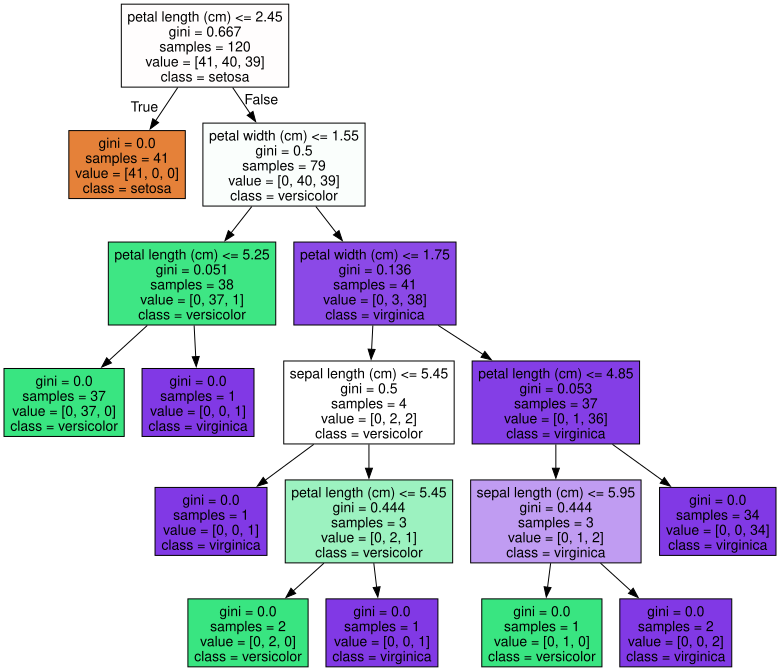

In [4]:
import graphviz
# 위에서 생성된 tree.dot 파일을 Graphviz가 읽어서 주피터 노트북상에서 시각화
with open("tree.dot") as f:
    dot_graph = f.read()
graphviz.Source(dot_graph)

### 시각화된 트리 읽는 법

그림을 보면 각 규칙에 따라 트리의 브랜치(branch) 노드와 말단 리프(leaf) 노드가 어떻게 구성되는지 한눈에 알 수 있음.

- 더 이상 자식 노드가 없는 노드가 **리프 노드**임. 리프 노드는 최종 클래스(레이블) 값이 결정되는 노드이며, 오직 하나의 클래스 값으로 최종 데이터가 구성되거나 리프 노드가 될 수 있는 하이퍼 파라미터 조건을 충족하면 리프 노드가 됨
- 자식 노드가 있는 노드는 **브랜치 노드**이며, 자식 노드를 만들기 위한 분할 규칙 조건을 가지고 있음

- `petal length (cm) <= 2.45` 같은 피처 조건: 자식 노드를 만들기 위한 규칙 조건임. 이 조건이 없으면 리프 노드임
- `gini`: 그 아래 `value = [ ]`로 주어진 데이터 분포에서의 지니 계수
- `samples`: 현재 규칙에 해당하는 데이터 건수
- `value = [ ]`: 클래스 값 기반의 데이터 건수. 붓꽃 데이터는 클래스 값이 0, 1, 2이고 각각 Setosa, Versicolor, Virginica 품종을 가리킴. 예를 들어 `value = [41, 40, 39]`라면 Setosa 41개, Versicolor 40개, Virginica 39개로 데이터가 구성돼 있다는 뜻
- `class`: 하위 노드를 가질 경우 value에서 가장 개수가 많은 클래스

가장 윗부분(1번 노드)부터 몇 단계 아래로 내려가며 트리가 어떻게 구성되는지 보면 다음과 같음. 루트 노드인 1번 노드의 지표 해석은 아래와 같음.
- samples = 120: 전체 데이터가 120개라는 의미
- value = [41, 40, 39]: Setosa 41개, Versicolor 40개, Virginica 39개로 데이터가 구성됨
- sample 120개가 value = [41, 40, 39] 분포로 되어 있으므로 지니 계수는 0.667
- `petal length (cm) <= 2.45` 규칙으로 자식 노드를 생성
- class = setosa: 하위 노드를 가질 경우 setosa의 개수가 41로 가장 많다는 의미

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

Feature importances:
[0.025 0.    0.555 0.42 ]
sepal length (cm) : 0.025
sepal width (cm) : 0.000
petal length (cm) : 0.555
petal width (cm) : 0.420


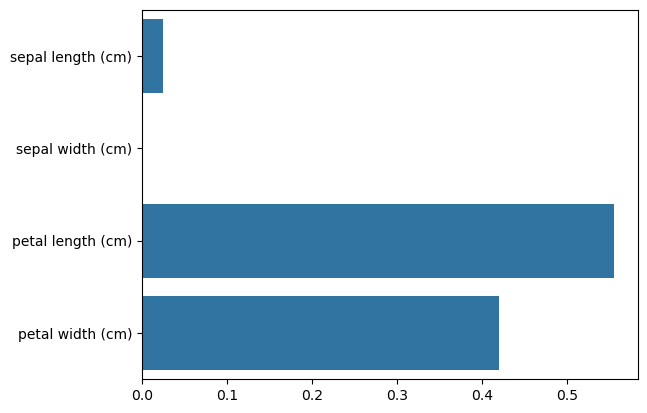

In [6]:
import seaborn as sns
import numpy as np
%matplotlib inline

# feature importance 추출
print("Feature importances:\n{0}".format(np.round(dt_clf.feature_importances_, 3)))

# feature별 importance 매핑
for name, value in zip(iris_data.feature_names, dt_clf.feature_importances_):
    print('{0} : {1:.3f}'.format(name, value))

# feature importance를 column 별로 시각화하기
sns.barplot(x=dt_clf.feature_importances_, y=iris_data.feature_names)
plt.show()

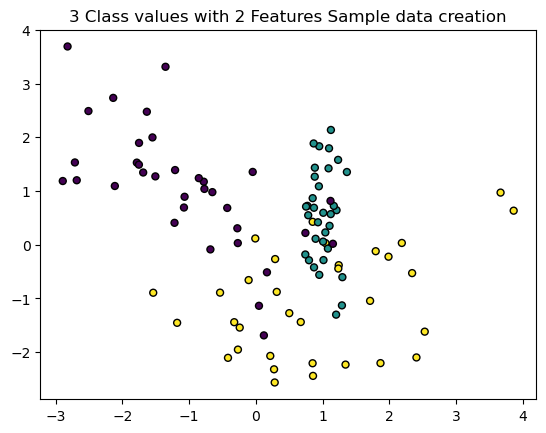

In [7]:
from sklearn.datasets import make_classification
import matplotlib.pyplot as plt
%matplotlib inline

plt.title("3 Class values with 2 Features Sample data creation")

# 2차원 시각화를 위해서 피처는 2개, 클래스는 3가지 유형의 분류 샘플 데이터 생성.
X_features, y_labels = make_classification(n_features=2, n_redundant=0, n_informative=2,
                                           n_classes=3, n_clusters_per_class=1, random_state=0)

# 그래프 형태로 2개의 피처로 2차원 좌표 시각화, 각 클래스 값은 다른 색깔로 표시됨.
plt.scatter(X_features[:, 0], X_features[:, 1], marker='o', c=y_labels, s=25, edgecolor='k')
plt.show()

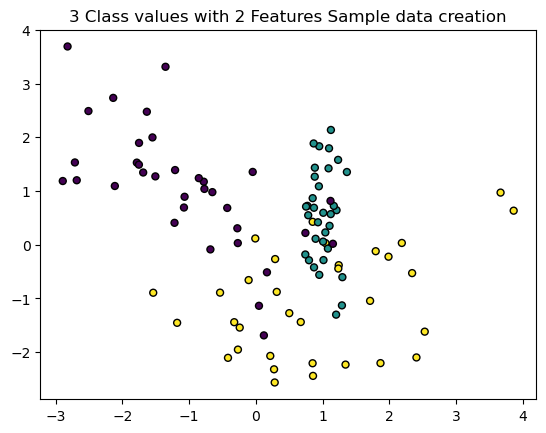

In [8]:
from sklearn.datasets import make_classification
import matplotlib.pyplot as plt
%matplotlib inline

plt.title("3 Class values with 2 Features Sample data creation")

# 2차원 시각화를 위해서 피처는 2개, 클래스는 3가지 유형의 분류 샘플 데이터 생성.
X_features, y_labels = make_classification(n_features=2, n_redundant=0, n_informative=2,
                                           n_classes=3, n_clusters_per_class=1, random_state=0)

# 그래프 형태로 2개의 피처로 2차원 좌표 시각화, 각 클래스 값은 다른 색깔로 표시됨.
plt.scatter(X_features[:, 0], X_features[:, 1], marker='o', c=y_labels, s=25, edgecolor='k')
plt.show()

In [9]:
import numpy as np

# Classifier의 Decision Boundary를 시각화 하는 함수
def visualize_boundary(model, X, y):
    fig,ax = plt.subplots()
    
    # 학습 데이타 scatter plot으로 나타내기
    ax.scatter(X[:, 0], X[:, 1], c=y, s=25, cmap='rainbow', edgecolor='k',
               clim=(y.min(), y.max()), zorder=3)
    ax.axis('tight')
    ax.axis('off')
    xlim_start , xlim_end = ax.get_xlim()
    ylim_start , ylim_end = ax.get_ylim()
    
    # 호출 파라미터로 들어온 training 데이타로 model 학습 . 
    model.fit(X, y)
    # meshgrid 형태인 모든 좌표값으로 예측 수행. 
    xx, yy = np.meshgrid(np.linspace(xlim_start,xlim_end, num=200),np.linspace(ylim_start,ylim_end, num=200))
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    
    # contourf() 를 이용하여 class boundary 를 visualization 수행. 
    n_classes = len(np.unique(y))
    contours = ax.contourf(xx, yy, Z, alpha=0.3,
                           levels=np.arange(n_classes + 1) - 0.5,
                           cmap='rainbow', clim=(y.min(), y.max()),
                           zorder=1)

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

def visualize_boundary(model, X, y):

    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.01),
                         np.arange(y_min, y_max, 0.01))

    Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    cmap_light = ListedColormap(['#FFAAAA', '#AAAAFF', '#AAFFAA'])
    cmap_bold = ListedColormap(['#FF0000', '#0000FF', '#00FF00'])

    plt.figure()
    plt.contourf(xx, yy, Z, cmap=cmap_light, alpha=0.8)
    plt.scatter(X[:, 0], X[:, 1], c=y, cmap=cmap_bold, s=25, edgecolor='k')
    plt.xlim(xx.min(), xx.max())
    plt.ylim(yy.min(), yy.max())
    plt.title("Decision Boundary")
    plt.xlabel("Feature 1")
    plt.ylabel("Feature 2")
    plt.show()

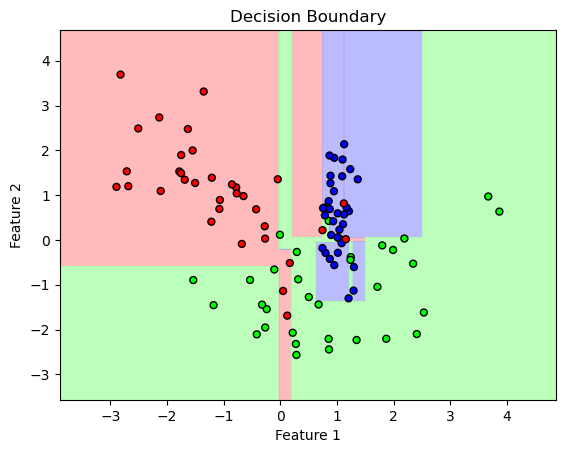

In [11]:
from sklearn.tree import DecisionTreeClassifier

# 특정한 트리 생성 제약 없는 결정 트리의 학습과 결정 경계 시각화.
dt_clf = DecisionTreeClassifier(random_state=156).fit(X_features, y_labels)
visualize_boundary(dt_clf, X_features, y_labels)
plt.show()

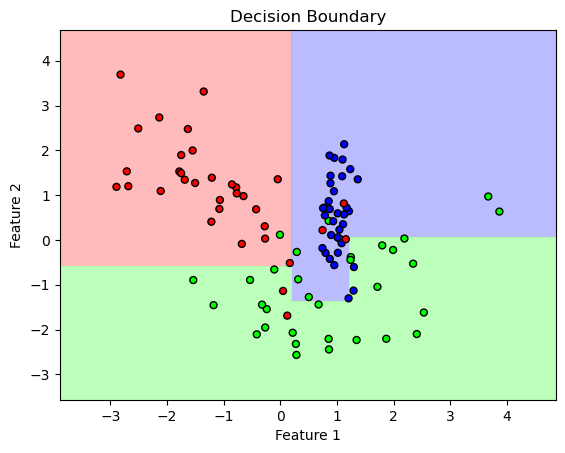

In [12]:
# min_samples_leaf=6으로 트리 생성 조건을 제약한 결정 경계 시각화
dt_clf = DecisionTreeClassifier(min_samples_leaf=6, random_state=156).fit(X_features, y_labels)
visualize_boundary(dt_clf, X_features, y_labels)

In [13]:
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

# features.txt 파일에는 피처 이름 index와 피처명이 공백으로 분리되어 있음. 이를 DataFrame으로 로드.
feature_name_df = pd.read_csv('./human_activity/features.txt', sep='\s+',
                              header=None, names=['column_index', 'column_name'])

# 피처명 index를 제거하고, 피처명만 리스트 객체로 생성한 뒤 샘플로 10개만 추출
feature_name = feature_name_df.iloc[:, 1].values.tolist()
print('전체 피처명에서 10개만 추출:', feature_name[:10])

전체 피처명에서 10개만 추출: ['tBodyAcc-mean()-X', 'tBodyAcc-mean()-Y', 'tBodyAcc-mean()-Z', 'tBodyAcc-std()-X', 'tBodyAcc-std()-Y', 'tBodyAcc-std()-Z', 'tBodyAcc-mad()-X', 'tBodyAcc-mad()-Y', 'tBodyAcc-mad()-Z', 'tBodyAcc-max()-X']


In [14]:
feature_dup_df = feature_name_df.groupby('column_name').count()
print(feature_dup_df[feature_dup_df['column_index'] > 1].count())
feature_dup_df[feature_dup_df['column_index'] > 1].head()

column_index    42
dtype: int64


,column_index
column_name,
"fBodyAcc-bandsEnergy()-1,16",3
"fBodyAcc-bandsEnergy()-1,24",3
"fBodyAcc-bandsEnergy()-1,8",3
"fBodyAcc-bandsEnergy()-17,24",3
"fBodyAcc-bandsEnergy()-17,32",3


In [15]:
def get_new_feature_name_df(old_feature_name_df):
    feature_dup_df = pd.DataFrame(data=old_feature_name_df.groupby('column_name').cumcount(),
                                  columns=['dup_cnt'])
    feature_dup_df = feature_dup_df.reset_index()
    new_feature_name_df = pd.merge(old_feature_name_df.reset_index(), feature_dup_df, how='outer')
    new_feature_name_df['column_name'] = new_feature_name_df[['column_name',
                                         'dup_cnt']].apply(lambda x : x[0]+'_'+str(x[1])
                                                           if x[1] >0 else x[0] , axis=1)
    new_feature_name_df = new_feature_name_df.drop(['index'], axis=1)
    return new_feature_name_df

In [16]:
import pandas as pd

def get_human_dataset( ):

    # 각 데이터 파일은 공백으로 분리되어 있으므로 read_csv에서 공백 문자를 sep으로 할당.
    feature_name_df = pd.read_csv('./human_activity/features.txt',sep='\s+',
                        header=None,names=['column_index','column_name'])

    # 중복된 피처명을 수정하는 get_new_feature_name_df()를 이용, 신규 피처명 DataFrame 생성.
    new_feature_name_df = get_new_feature_name_df(feature_name_df)

    # DataFrame에 피처명을 칼럼으로 부여하기 위해 리스트 객체로 다시 변환
    feature_name = new_feature_name_df.iloc[:, 1].values.tolist()

    # 학습 피처 데이터세트와 테스트 피처 데이터를 DataFrame으로 로딩. 칼럼명은 feature_name 적용
    X_train = pd.read_csv('./human_activity/train/X_train.txt',sep='\s+', names=feature_name )
    X_test = pd.read_csv('./human_activity/test/X_test.txt',sep='\s+', names=feature_name)

    # 학습 레이블과 테스트 레이블 데이터를 DataFrame으로 로딩하고 칼럼명은 action으로 부여
    y_train = pd.read_csv('./human_activity/train/y_train.txt',sep='\s+',header=None,names=['action'])
    y_test = pd.read_csv('./human_activity/test/y_test.txt',sep='\s+',header=None,names=['action'])

    # 로드된 학습/테스트용 DataFrame을 모두 반환
    return X_train, X_test, y_train, y_test

X_train, X_test, y_train, y_test = get_human_dataset()

In [17]:
print('## 학습 피처 데이터셋 info()')
print(X_train.info())

## 학습 피처 데이터셋 info()
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7352 entries, 0 to 7351
Columns: 561 entries, tBodyAcc-mean()-X to angle(Z,gravityMean)
dtypes: float64(561)
memory usage: 31.5 MB
None


In [18]:
print(y_train['action'].value_counts())

action
6    1407
5    1374
4    1286
1    1226
2    1073
3     986
Name: count, dtype: int64


In [19]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

# 예제 반복 시마다 동일한 예측 결과 도출을 위해 random_state 설정
dt_clf = DecisionTreeClassifier(random_state=156)
dt_clf.fit(X_train, y_train)
pred = dt_clf.predict(X_test)
accuracy = accuracy_score(y_test, pred)
print('결정 트리 예측 정확도: {0:.4f}'.format(accuracy))

# DecisionTreeClassifier의 하이퍼 파라미터 추출
print('DecisionTreeClassifier 기본 하이퍼 파라미터:\n', dt_clf.get_params())

결정 트리 예측 정확도: 0.8548
DecisionTreeClassifier 기본 하이퍼 파라미터:
 {'ccp_alpha': 0.0, 'class_weight': None, 'criterion': 'gini', 'max_depth': None, 'max_features': None, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 1, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'random_state': 156, 'splitter': 'best'}


In [20]:
from sklearn.model_selection import GridSearchCV

params = {
    'max_depth' : [ 6, 8 ,10, 12, 16 ,20, 24],
    'min_samples_split': [16]
}

grid_cv = GridSearchCV(dt_clf, param_grid=params, scoring='accuracy', cv=5, verbose=1 )
grid_cv.fit(X_train, y_train)
print('GridSearchCV 최고 평균 정확도 수치: {0:.4f}'.format(grid_cv.best_score_))
print('GridSearchCV 최적 하이퍼 파라미터:', grid_cv.best_params_)

Fitting 5 folds for each of 7 candidates, totalling 35 fits
GridSearchCV 최고 평균 정확도 수치: 0.8549
GridSearchCV 최적 하이퍼 파라미터: {'max_depth': 8, 'min_samples_split': 16}


In [21]:
# GridSearchCV 객체의 cv_results_ 속성을 DataFrame으로 생성.
cv_results_df = pd.DataFrame(grid_cv.cv_results_)

# max_depth 파라미터 값과 그때의 테스트 세트, 학습 데이터 세트의 정확도 수치 추출
cv_results_df[['param_max_depth', 'mean_test_score']]

,param_max_depth,mean_test_score
0,6,0.847662
1,8,0.854879
2,10,0.852705
3,12,0.845768
4,16,0.847127
5,20,0.848624
6,24,0.848624


In [22]:
max_depths = [ 6, 8, 10, 12, 16 ,20, 24]
# max_depth 값을 변화시키면서 그때마다 학습과 테스트 세트에서의 예측 성능 측정
for depth in max_depths:
    dt_clf = DecisionTreeClassifier(max_depth=depth, min_samples_split=16, random_state=156)
    dt_clf.fit(X_train, y_train)
    pred = dt_clf.predict(X_test)
    accuracy = accuracy_score(y_test, pred)
    print('max_depth = {0} 정확도: {1:.4f}'.format(depth, accuracy))

max_depth = 6 정확도: 0.8551
max_depth = 8 정확도: 0.8717
max_depth = 10 정확도: 0.8599
max_depth = 12 정확도: 0.8571
max_depth = 16 정확도: 0.8599
max_depth = 20 정확도: 0.8565
max_depth = 24 정확도: 0.8565


In [23]:
params = {
    'max_depth' : [ 8, 12, 16, 20],
    'min_samples_split' : [16, 24],
}

grid_cv = GridSearchCV(dt_clf, param_grid=params, scoring='accuracy', cv=5, verbose=1 )
grid_cv.fit(X_train, y_train)
print('GridSearchCV 최고 평균 정확도 수치: {0:.4f}'.format(grid_cv.best_score_))
print('GridSearchCV 최적 하이퍼 파라미터:', grid_cv.best_params_)

Fitting 5 folds for each of 8 candidates, totalling 40 fits
GridSearchCV 최고 평균 정확도 수치: 0.8549
GridSearchCV 최적 하이퍼 파라미터: {'max_depth': 8, 'min_samples_split': 16}


In [24]:
best_df_clf = grid_cv.best_estimator_
pred1 = best_df_clf.predict(X_test)
accuracy = accuracy_score(y_test, pred1)
print('결정 트리 예측 정확도:{0:.4f}'.format(accuracy))

결정 트리 예측 정확도:0.8717


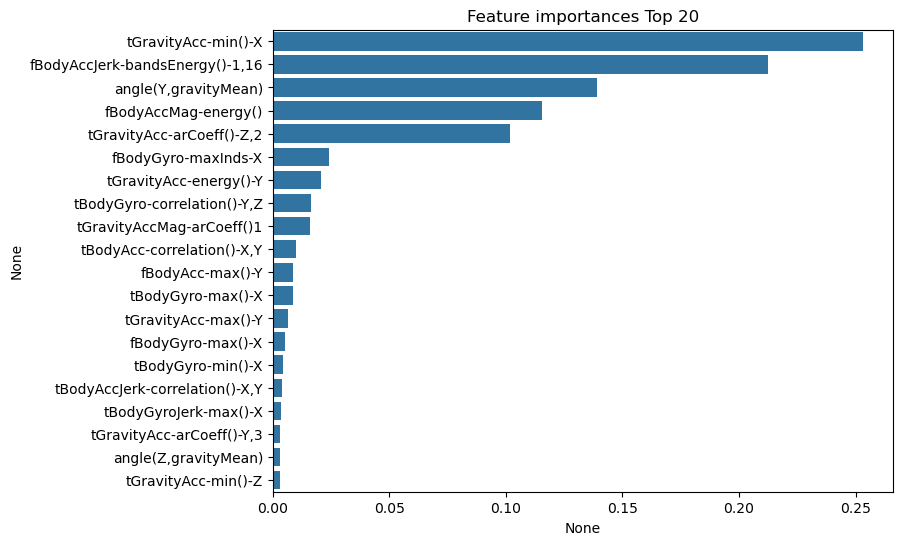

In [25]:
import seaborn as sns

ftr_importances_values = best_df_clf.feature_importances_
# Top 중요도로 정렬을 쉽게 하고, 시본(Seaborn)의 막대그래프로 쉽게 표현하기 위해 Series 변환
ftr_importances = pd.Series(ftr_importances_values, index=X_train.columns  )
# 중요도값 순으로 Series를 정렬
ftr_top20 = ftr_importances.sort_values(ascending=False)[:20]
plt.figure(figsize=(8, 6))
plt.title('Feature importances Top 20')
sns.barplot(x=ftr_top20, y = ftr_top20.index)
plt.show()